**PROJECT 34:**

Jaakko Hietikko 2214871

Jani-Matti Laasonen Y68417011

Urho Väyrynen 2214968

**1. Data Exploration and Preprocessing:** Explore the distribution of tweets by sentiment, Age of User,
Country, and Time of Tweet. Visualize the data using appropriate charts such as bar charts, histograms,
and heatmaps. 

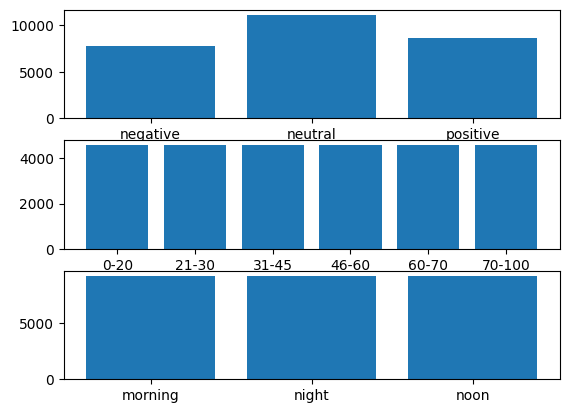

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

data = pd.read_csv("train.csv", encoding="latin1")
data_sentiment = data["sentiment"]
data_age_of_user = data["Age of User"]
data_country = data["Country"]
data_time_of_tweet = data["Time of Tweet"]
data_density = data["Density (P/Km²)"]
y = data_sentiment.value_counts().sort_index()
z = data_age_of_user.value_counts().sort_index()
x = data_country.value_counts().sort_index()
i = data_time_of_tweet.value_counts().sort_index()
j = data_density.value_counts().sort_index()

fig, ax = plt.subplots(3)

ax[0].bar(y.index, y.values)
ax[1].bar(z.index, z.values)
ax[2].bar(i.index, i.values)

plt.show()

country_df = x.rename_axis("Country").reset_index(name="Count")

fig = px.choropleth(
    country_df,
    locations="Country",
    locationmode="country names",
    color="Count",
    hover_name="Country",
    color_continuous_scale="Viridis",
    title="Number of Instances per Country"
)

fig.show()

**2. Exploratory Analysis of Demographics:** Analyze the correlation between demographic
information (e.g., Age of User, Country) and the sentiment of the tweets. Identify if certain age groups
or countries tend to express more positive, negative, or neutral sentiments. Also. analyze how density
affects sentiment patterns.

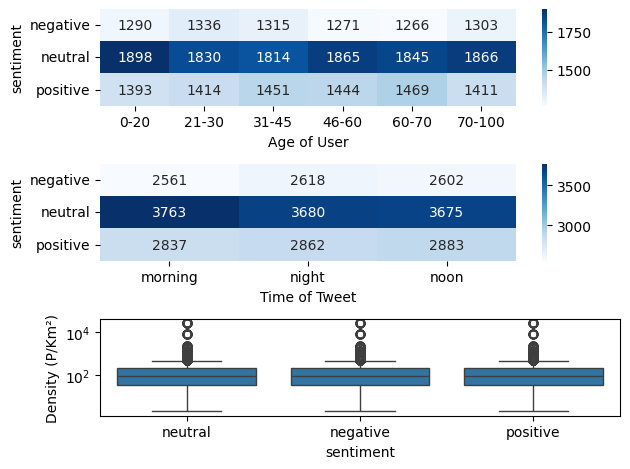

Spearman correlation between sentiment and time of tweet: 0.000
P-value: 0.9477
Spearman correlation between sentiment and age of user: 0.006
P-value: 0.3156
Spearman correlation between sentiment and density: 0.003
P-value: 0.5747


In [3]:
import numpy as np
import seaborn as sns
from scipy.stats import spearmanr

cross_table = pd.crosstab(data_sentiment, data_age_of_user)
cross_table2 = pd.crosstab(data_sentiment, data_time_of_tweet)
cross_table3 = pd.crosstab(data_sentiment, data_density)

fig, ax = plt.subplots(3)

sns.heatmap(cross_table, annot=True, fmt="d", cmap="Blues", ax=ax[0])
sns.heatmap(cross_table2, annot=True, fmt="d", cmap="Blues", ax=ax[1])
sns.boxplot(data=data, x="sentiment",y="Density (P/Km²)", ax=ax[2])
ax[2].set_yscale("log")

plt.tight_layout()
plt.show()

def correlation(data1, data2, subject1, subject2):
    rho, p_value = spearmanr(
        data1,
        data2,
        nan_policy="omit"
    )
    
    print(f"Spearman correlation between {subject1} and {subject2}: {rho:.3f}")
    print(f"P-value: {p_value:.4f}")

correlation(data["sentiment"], data["Time of Tweet"], "sentiment", "time of tweet")
correlation(data["sentiment"], data["Age of User"], "sentiment", "age of user")
correlation(data["sentiment"], data["Density (P/Km²)"], "sentiment", "density")

**3. Time of Tweet and Sentiment Trends:** Investigate how the time of tweet (morning, noon, night)
correlates with sentiment. Do people tend to tweet more positively or negatively at certain times of the
day? Visualize sentiment trends over time to identify any patterns (e.g., higher negativity during late
hours or weekends)

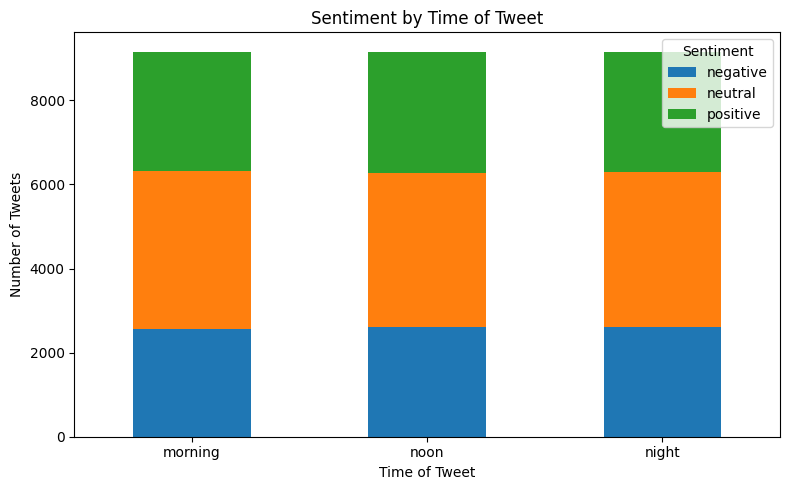

In [4]:
time_sentiment = pd.crosstab(data['Time of Tweet'], data['sentiment']).reindex(['morning', 'noon', 'night'], fill_value=0)

time_sentiment.plot(kind='bar', stacked=True, figsize=(8, 5))
plt.title('Sentiment by Time of Tweet')
plt.xlabel('Time of Tweet')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=0)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

**4. Topic Modeling with LDA on Tweets:** The main aim of this task is to use LDA (Latent Dirichlet
Allocation) to discover hidden topics within the tweet dataset and analyze how these topics correlate
with different sentiment classes (positive, neutral, negative). Apply LDA to the text or selected_text
field to identify the most common topics discussed in the tweets. After extracting the topics, categorize
tweets based on the most likely topic and analyze the distribution of sentiment across different topics.
Visualize the topics using word clouds or bar charts to interpret the most frequent words associated
with each topic. 

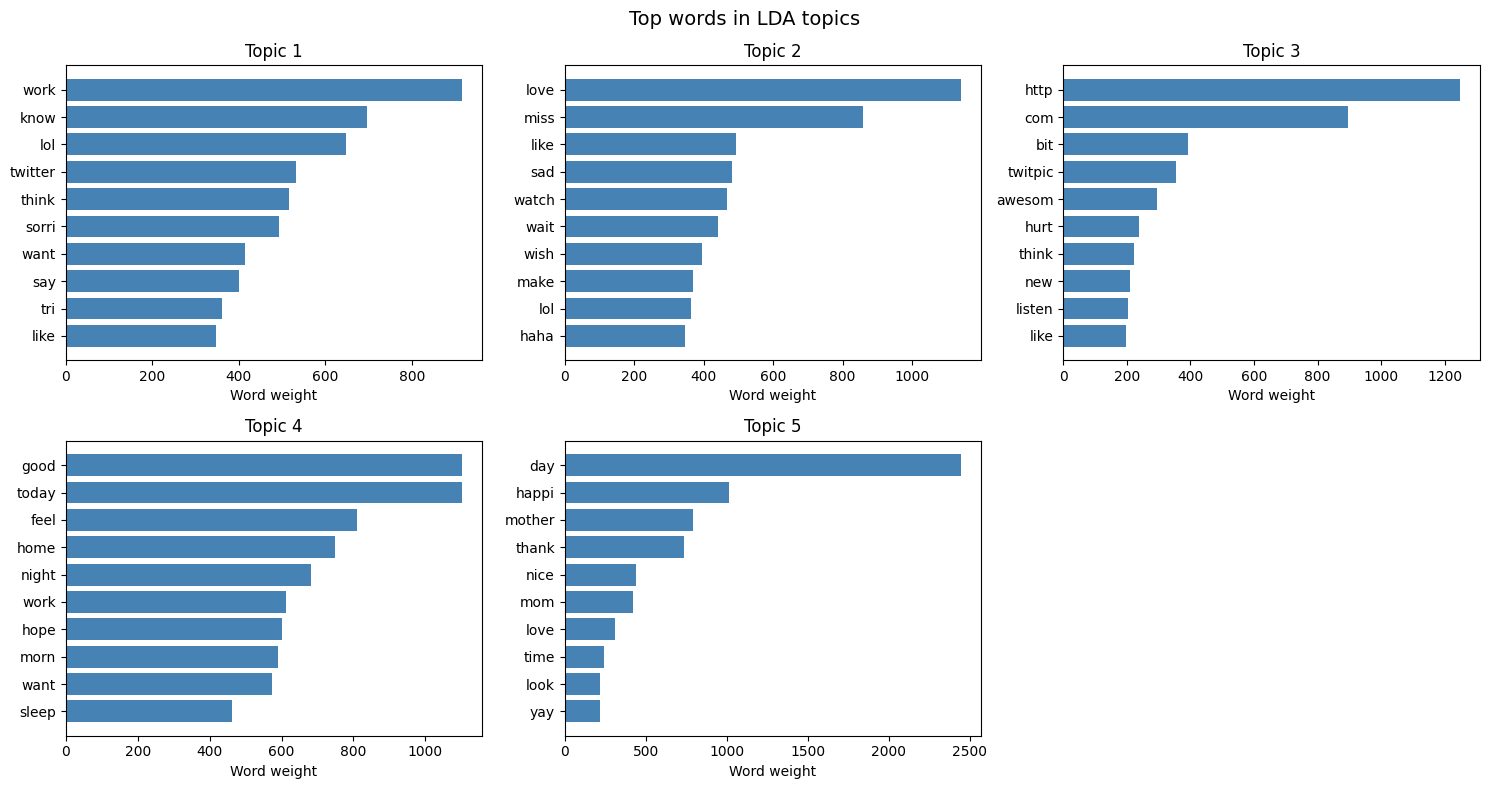

Tweet counts by dominant topic and sentiment:


sentiment,negative,neutral,positive
Topic,,,
1,2113,3459,1466
2,1756,2325,2055
3,1045,1577,1029
4,2373,2568,1851
5,486,1078,2178


Sentiment distribution within each topic (%):


sentiment,negative,neutral,positive
Topic,,,
1,30.0,49.1,20.8
2,28.6,37.9,33.5
3,28.6,43.2,28.2
4,34.9,37.8,27.3
5,13.0,28.8,58.2


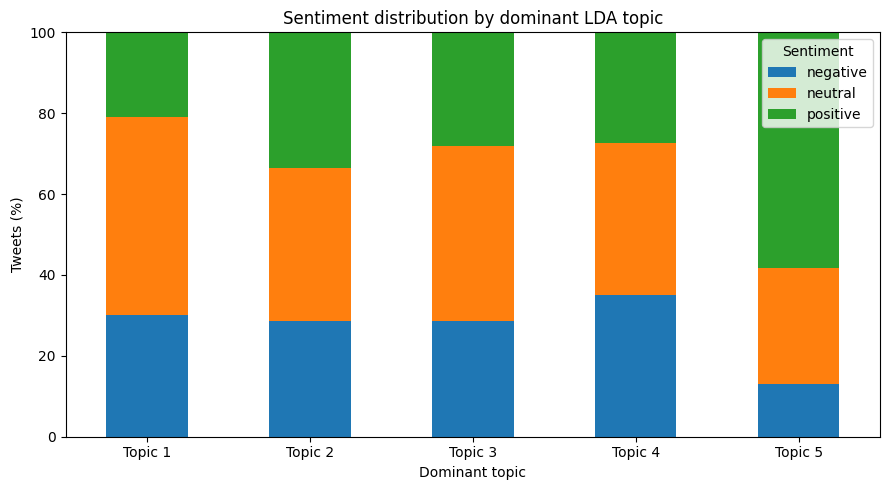

In [22]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from nltk.stem import PorterStemmer
from nltk.corpus import stopwords
import re

def clean_text(text):
    #Function for cleaning the text from numbers, stopwords and non-words.
    text_words_only = re.findall(r'\b[A-Za-z][a-z]{2,}\b', text)
    #Removing stopwords
    stop = stopwords.words("english")
    clean_text = [w for w in text_words_only if w not in stop]
    return clean_text

stemmer = PorterStemmer()

lda_data = data.loc[
    data["text"].notna() & data["sentiment"].notna(), ["text", "sentiment"]
].copy()

tokenized = [
    [stemmer.stem(word) for word in clean_text(str(text).lower())]
    for text in lda_data["text"]
]

tokenized_joined = [" ".join(text) for text in tokenized]

lda_data["text"] = tokenized_joined
lda_data = lda_data.loc[lda_data["text"] != ""].reset_index(drop=True)

vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 1),
    min_df=5,
    max_df=0.95,
    max_features=1000,
)
doc_term_matrix = vectorizer.fit_transform(lda_data["text"])

n_topics = 5
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    learning_method="batch",
    max_iter=10,
)
doc_topic_distribution = lda_model.fit_transform(doc_term_matrix)
lda_data["Topic"] = doc_topic_distribution.argmax(axis=1) + 1

feature_names = vectorizer.get_feature_names_out()
n_top_words = 10
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for topic_id, topic_weights in enumerate(lda_model.components_):
    top_word_indices = topic_weights.argsort()[-n_top_words:][::-1]
    top_words = feature_names[top_word_indices]
    top_weights = topic_weights[top_word_indices]
    axes[topic_id].barh(top_words[::-1], top_weights[::-1], color="steelblue")
    axes[topic_id].set_title(f"Topic {topic_id + 1}")
    axes[topic_id].set_xlabel("Word weight")

axes[-1].axis("off")
fig.suptitle("Top words in LDA topics", fontsize=14)
fig.tight_layout()
plt.show()

sentiment_order = [
    label
    for label in ["negative", "neutral", "positive"]
    if label in lda_data["sentiment"].unique()
]
sentiment_order += sorted(
    set(lda_data["sentiment"].unique()) - set(sentiment_order)
)
topic_sentiment_counts = pd.crosstab(
    lda_data["Topic"], lda_data["sentiment"]
).reindex(columns=sentiment_order, fill_value=0)
topic_sentiment_percent = topic_sentiment_counts.div(
    topic_sentiment_counts.sum(axis=1), axis=0
).mul(100)

print("Tweet counts by dominant topic and sentiment:")
display(topic_sentiment_counts)
print("Sentiment distribution within each topic (%):")
display(topic_sentiment_percent.round(1))

topic_sentiment_percent.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Sentiment distribution by dominant LDA topic")
plt.xlabel("Dominant topic")
plt.ylabel("Tweets (%)")
plt.xticks(
    ticks=range(n_topics),
    labels=[f"Topic {topic_id + 1}" for topic_id in range(n_topics)],
    rotation=0,
)
plt.ylim(0, 100)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

**5. Coherence-Based Topic Model Tuning:** The purpose of the task is to optimize LDA’s performance
by tuning the number of topics based on topic coherence. Experiment with different numbers of topics
for LDA (e.g., 5, 10, 15, 20) and use a coherence score (e.g., CV coherence) to evaluate the quality of
the topics. Fine-tune the number of topics based on coherence score to identify the most meaningful
number of topics for the dataset. 

In [6]:
from gensim.models import CoherenceModel
from gensim.corpora import Dictionary

topic_numbers = [5, 10, 15, 20]

texts = [
    vectorizer.build_analyzer()(tweet)
    for tweet in lda_data["text"]
]

coherence_scores = []
lda_models = {}

for k in topic_numbers:
    print(f"Training LDA with {k} topics...")

    model = LatentDirichletAllocation(
        n_components=k,
        random_state=42,
        learning_method="batch",
        max_iter=10,
    )

    model.fit(doc_term_matrix)

    topics = []
    for topic_weights in model.components_:
        top_indices = topic_weights.argsort()[-10:][::-1]
        topics.append(feature_names[top_indices].tolist())

    dictionary = Dictionary(texts)
    
    coherence_model = CoherenceModel(
        topics=topics,
        texts=texts,
        dictionary=dictionary,
        coherence="c_v",
        processes=1,
    )

    score = coherence_model.get_coherence()

    coherence_scores.append(score)
    lda_models[k] = model

    print(f"Topics: {k}, CV coherence: {score:.4f}")

results = pd.DataFrame({
    "Number of topics": topic_numbers,
    "CV coherence": coherence_scores
})

display(results.sort_values("CV coherence", ascending=False))

best_k = topic_numbers[coherence_scores.index(max(coherence_scores))]
best_lda_model = lda_models[best_k]

print(f"Best number of topics: {best_k}")
print(f"Highest CV coherence: {max(coherence_scores):.4f}")

Training LDA with 5 topics...
Topics: 5, CV coherence: 0.4548
Training LDA with 10 topics...
Topics: 10, CV coherence: 0.4151
Training LDA with 15 topics...
Topics: 15, CV coherence: 0.3618
Training LDA with 20 topics...
Topics: 20, CV coherence: 0.3294


,Number of topics,CV coherence
0,5,0.454820
1,10,0.415109
2,15,0.361816
3,20,0.329394


Best number of topics: 5
Highest CV coherence: 0.4548


**6. Word Embeddings for Topic Similarity:** The aim of this task is to use Word2Vec or BERT-based
embeddings to analyze the similarity between different topics extracted via LDA (Task 4). Generate
word embeddings for the most frequent words in each LDA topic using Word2Vec or BERT. Calculate
the cosine similarity between different topics based on their word embeddings to see which topics are
semantically similar. Visualize the similarity between topics using heatmaps or dendrograms. 

In [ ]:
from gensim.models import Word2Vec
from sklearn.metrics.pairwise import cosine_similarity


w2v_model = Word2Vec(
    sentences=tokenized,
    vector_size=100,
    window=3,
    min_count=1,
    epochs=10)



In [36]:
topics = []
for topic_id, topic_weights in enumerate(lda_model.components_):
    top_word_indices = topic_weights.argsort()[-n_top_words:][::-1]
    topics.append(feature_names[top_word_indices].tolist())

print(topics)

def topic_avg_similarity(topic1, topic2):
    #Takes in already W2V topics
    total = 0
    for v_t1 in topic1: 
        for v_t2 in topic2:
            sim = cosine_similarity(v_t1.reshape(1, -1), v_t2.reshape(1, -1))[0, 0]
            total = total + sim
    return total / (len(topic1) * len(topic2))

def topic_similarity_avgvec(topic1, topic2): 
    #Takes in already W2V topics
    avg_t1 = np.mean(topic1, axis=0)
    avg2_t2 = np.mean(topic2, axis=0)
    sim = sim = cosine_similarity(avg_t1.reshape(1, -1), avg2_t2.reshape(1, -1))[0, 0]
    return sim

w2v_topics = [[w2v_model.wv[word] for word in topic] for topic in topics]

avgsimilarity_matrix = np.zeros((n_topics, n_topics))

for i in range(n_topics):
    for j in range(n_topics):
        if w2v_topics[i] and w2v_topics[j]:
            avgsimilarity_matrix[i, j] = topic_avg_similarity(
                w2v_topics[i], w2v_topics[j]
            )
        else:
            avgsimilarity_matrix[i, j] = np.nan




labels = [f"Topic {i + 1}" for i in range(n_topics)]

topic_avgsimilarities = pd.DataFrame(
    avgsimilarity_matrix,
    index=labels,
    columns=labels
)

avgvec_sim_matrix =  np.zeros((n_topics, n_topics))

for i in range(n_topics):
    for j in range(n_topics):
        if w2v_topics[i] and w2v_topics[j]:
            avgvec_sim_matrix[i, j] = topic_similarity_avgvec(
                w2v_topics[i], w2v_topics[j]
            )
        else:
            avgvec_sim_matrix[i, j] = np.nan

[['work', 'know', 'lol', 'twitter', 'think', 'sorri', 'want', 'say', 'tri', 'like'], ['love', 'miss', 'like', 'sad', 'watch', 'wait', 'wish', 'make', 'lol', 'haha'], ['http', 'com', 'bit', 'twitpic', 'awesom', 'hurt', 'think', 'new', 'listen', 'like'], ['good', 'today', 'feel', 'home', 'night', 'work', 'hope', 'morn', 'want', 'sleep'], ['day', 'happi', 'mother', 'thank', 'nice', 'mom', 'love', 'time', 'look', 'yay']]


         Topic 1  Topic 2  Topic 3  Topic 4  Topic 5
Topic 1    0.825    0.751    0.645    0.716    0.648
Topic 2    0.751    0.760    0.635    0.704    0.686
Topic 3    0.645    0.635    0.659    0.552    0.586
Topic 4    0.716    0.704    0.552    0.781    0.685
Topic 5    0.648    0.686    0.586    0.685    0.757
[[1.    0.946 0.817 0.886 0.792]
 [0.946 1.    0.84  0.909 0.884]
 [0.817 0.84  1.    0.704 0.783]
 [0.886 0.909 0.704 1.    0.876]
 [0.792 0.884 0.783 0.876 1.   ]]


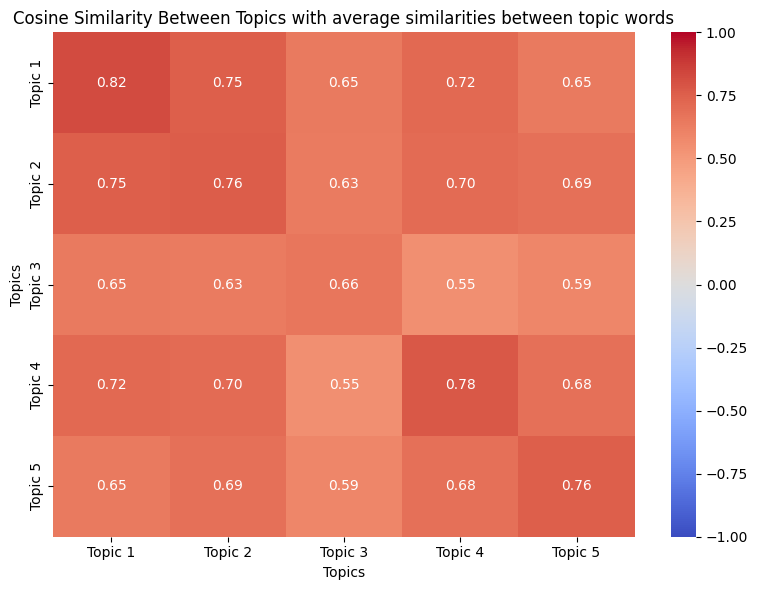

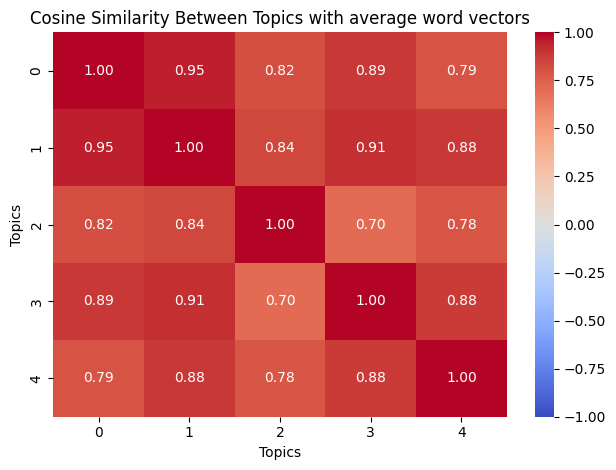

In [ ]:

print(topic_avgsimilarities.round(3))

plt.figure(figsize=(8, 6))

sns.heatmap(
    topic_avgsimilarities,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Cosine Similarity Between Topics with average similarities between topic words")
plt.xlabel("Topics")
plt.ylabel("Topics")
plt.tight_layout()
plt.show()


sns.heatmap(
    avgvec_sim_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Cosine Similarity Between Topics with average word vectors")
plt.xlabel("Topics")
plt.ylabel("Topics")
plt.tight_layout()
plt.show()